## Cell 1 — Install libraries & check device

In [1]:
## ── Cell 1 : Install & imports ──────────────────────────────────────────
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install monai tifffile imagecodecs gdown
!pip -q install -U scikit-image

import torch
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

import os, glob, cv2, numpy as np, tifffile as tiff
import matplotlib.pyplot as plt, matplotlib.patches as patches
import pandas as pd
from tqdm.auto import tqdm
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from monai.losses import DiceLoss
from segment_anything.utils.transforms import ResizeLongestSide

print('numpy', np.__version__)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.9/28.9 MB 62.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 103.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.1 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 73.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cucim-cu12 26.2.0 requires scikit-image<0.26.0,>=0.19.0, but you have scikit-image 0.26.0 which is incompatible.
Torch: 2.11.0+cu128 | CUDA: True
numpy 2.0.2


## Cell 1b — Mount Drive & set persistent checkpoint dir

Run this once per session, right after Cell 1. All checkpoint saves/loads in
Cell 7 and Cell 12 are routed through `ckpt_path(...)` so they land in Drive
and survive a runtime disconnect.

In [2]:
## ── Cell 1b : Persist checkpoints to Google Drive (survives disconnects) ──
from google.colab import drive
drive.mount('/content/drive')

import os
CKPT_DIR = '/content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

def ckpt_path(name):
    """All torch.save / torch.load / os.path.exists calls should go through this,
    so checkpoints land in Drive instead of the ephemeral runtime disk."""
    return os.path.join(CKPT_DIR, name)

print('Checkpoints will be saved to:', CKPT_DIR)
print('Existing checkpoints found:')
for f in sorted(os.listdir(CKPT_DIR)):
    print(' -', f)


Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints
Existing checkpoints found:


## Cell 2 — Download dataset & build pairs

We build **two** pair lists from the same DIC-C2DH-HeLa download:
- `pairs_seg` — iterates SEG silver-truth masks (Model 1)
- `pairs_tra` — iterates TRA gold-truth masks (Model 2)

In [3]:
## ── Cell 2 : Download & build pairs ─────────────────────────────────────
!wget -q http://data.celltrackingchallenge.net/training-datasets/DIC-C2DH-HeLa.zip
!unzip -q -o DIC-C2DH-HeLa.zip -d data
ROOT = 'data/DIC-C2DH-HeLa'


# ── Model 1 pairs: anchor on ST/SEG silver-truth masks ───────────────────
def build_pairs_seg(root):
    """Each tuple: (img_path, seg_path, tra_path_or_None)"""
    pairs = []
    for seq in ['01', '02']:
        seg_dir = os.path.join(root, f'{seq}_ST', 'SEG')
        for seg_path in sorted(glob.glob(os.path.join(seg_dir, 'man_seg*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(seg_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            tra_path = os.path.join(root, f'{seq}_GT', 'TRA', f'man_track{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path,
                    tra_path if os.path.exists(tra_path) else None
                ))
    return pairs


# ── Model 2 pairs: anchor on GT/TRA gold-truth masks ─────────────────────
def build_pairs_tra(root):
    """Each tuple: (img_path, seg_path_or_None, tra_path)"""
    pairs = []
    for seq in ['01', '02']:
        tra_dir = os.path.join(root, f'{seq}_GT', 'TRA')
        for tra_path in sorted(glob.glob(os.path.join(tra_dir, 'man_track*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(tra_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            seg_dir  = os.path.join(root, f'{seq}_ST', 'SEG')
            seg_path = os.path.join(seg_dir, f'man_seg{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path if os.path.exists(seg_path) else None,
                    tra_path
                ))
    return pairs


pairs_seg = build_pairs_seg(ROOT)
pairs_tra = build_pairs_tra(ROOT)

print(f'SEG pairs : {len(pairs_seg)}')
print(f'TRA pairs : {len(pairs_tra)}  (more frames — every tracked frame is included)')

SEG pairs : 168
TRA pairs : 168  (more frames — every tracked frame is included)


## Cell 3 — Train / Val / Test split (60 / 20 / 20)

In [4]:
## ── Cell 3 : Split ───────────────────────────────────────────────────────
def split_pairs(pairs, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(pairs))
    n   = len(pairs)
    train = [pairs[i] for i in idx[:int(.6*n)]]
    val   = [pairs[i] for i in idx[int(.6*n):int(.8*n)]]
    test  = [pairs[i] for i in idx[int(.8*n):]]
    return train, val, test

train_seg, val_seg, test_seg = split_pairs(pairs_seg)
train_tra, val_tra, test_tra = split_pairs(pairs_tra)

print(f'SEG  → train={len(train_seg)}  val={len(val_seg)}  test={len(test_seg)}')
print(f'TRA  → train={len(train_tra)}  val={len(val_tra)}  test={len(test_tra)}')

SEG  → train=100  val=34  test=34
TRA  → train=100  val=34  test=34


## Cell 4 — Visualise raw data (SEG vs TRA mask)

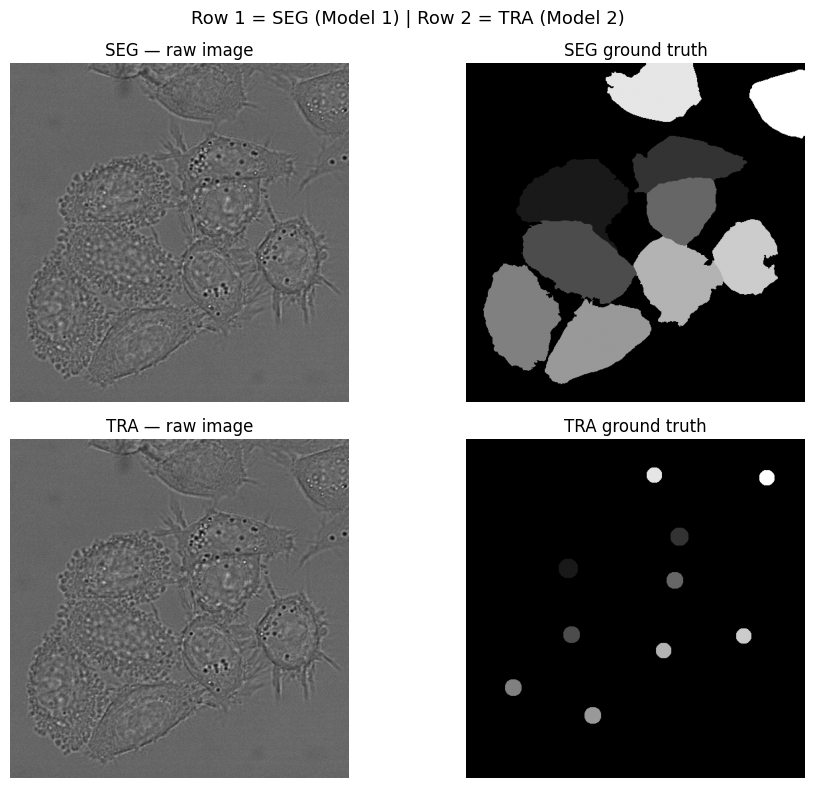

In [5]:
## ── Cell 4 : Visualise ───────────────────────────────────────────────────
def instance_to_grayscale(mask):
    """Each instance gets a unique grayscale shade for display."""
    mask = mask.astype(np.int32)
    ids  = np.unique(mask); ids = ids[ids != 0]
    out  = np.zeros_like(mask, dtype=np.float32)
    for i, uid in enumerate(ids):
        out[mask == uid] = (i + 1) / len(ids)
    return out

# Show one SEG sample and one TRA sample side by side
img_s  = tiff.imread(pairs_seg[0][0])
seg_m  = tiff.imread(pairs_seg[0][1])

img_t  = tiff.imread(pairs_tra[0][0])
tra_m  = tiff.imread(pairs_tra[0][2])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0,0].imshow(img_s,                     cmap='gray'); axes[0,0].set_title('SEG — raw image');  axes[0,0].axis('off')
axes[0,1].imshow(instance_to_grayscale(seg_m), cmap='gray', vmin=0, vmax=1); axes[0,1].set_title('SEG ground truth'); axes[0,1].axis('off')
axes[1,0].imshow(img_t,                     cmap='gray'); axes[1,0].set_title('TRA — raw image');  axes[1,0].axis('off')
axes[1,1].imshow(instance_to_grayscale(tra_m), cmap='gray', vmin=0, vmax=1); axes[1,1].set_title('TRA ground truth'); axes[1,1].axis('off')
plt.suptitle('Row 1 = SEG (Model 1) | Row 2 = TRA (Model 2)', fontsize=13)
plt.tight_layout(); plt.show()

## Cell 5 — Shared helper functions

In [6]:
## ── Cell 5 : Shared helpers ──────────────────────────────────────────────
transform = ResizeLongestSide(1024)

def preprocess_image(img2d):
    """Grayscale → normalised RGB float32 in [0, 255]."""
    rgb = np.repeat(img2d[..., None].astype(np.float32), 3, axis=-1)
    return (rgb - rgb.min()) / (np.ptp(rgb) + 1e-8) * 255.0

def bbox_from_mask(bm):
    """Tight bounding box [x1, y1, x2, y2] around all non-zero pixels."""
    ys, xs = np.where(bm > 0)
    if len(xs) == 0:
        return None
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def get_instance_boxes(mask):
    """One bounding box per instance ID."""
    ids = np.unique(mask); ids = ids[ids != 0]
    boxes = []
    for obj_id in ids:
        ys, xs = np.where(mask == obj_id)
        if len(xs) == 0: continue
        boxes.append((obj_id, np.array([xs.min(), ys.min(), xs.max(), ys.max()])))
    return boxes

def metrics(pred, gt):
    """Returns (Dice, IoU, Precision, Recall)."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = (pred & gt).sum()
    union = (pred | gt).sum()
    dice  = 2 * inter / (pred.sum() + gt.sum() + 1e-8)
    iou   = inter / (union + 1e-8)
    prec  = inter / (pred.sum() + 1e-8)
    rec   = inter / (gt.sum()   + 1e-8)
    return dice, iou, prec, rec

def box_iou(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter  = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-8)

print('Shared helpers defined.')

Shared helpers defined.


## Cell 6 — Load MedSAM (pretrained)

In [7]:
## ── Cell 6 : Load MedSAM ─────────────────────────────────────────────────
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O sam_vit_b.pth

# Try Google Drive first, fall back to Hugging Face mirror if it's rate-limited/blocked
!gdown -q 1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_ -O medsam_vit_b.pth || echo 'gdown failed, trying HF mirror...'

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    print('Falling back to Hugging Face mirror...')
    !wget -q https://huggingface.co/SansuiHan/medical_models/resolve/main/medsam_vit_b.pth -O medsam_vit_b.pth

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    raise RuntimeError('MedSAM checkpoint missing or corrupt.')

from segment_anything import sam_model_registry

def load_medsam(ckpt='medsam_vit_b.pth'):
    model = sam_model_registry['vit_b'](checkpoint=None)
    model.load_state_dict(torch.load(ckpt, map_location='cpu'), strict=False)
    return model.to(DEVICE)

medsam = load_medsam()
medsam.eval()
print('MedSAM loaded:', round(os.path.getsize('medsam_vit_b.pth') / 1e6, 1), 'MB')


@torch.no_grad()
def medsam_predict(model, img2d, box):
    """Single box → binary mask."""
    H, W = img2d.shape
    img_uint8  = preprocess_image(img2d).astype(np.uint8)
    in_img     = transform.apply_image(img_uint8)
    in_t       = torch.as_tensor(in_img).permute(2, 0, 1)[None].float().to(DEVICE)
    in_t       = model.preprocess(in_t)
    emb        = model.image_encoder(in_t)

    box_arr = np.array(box, dtype=np.float32)
    box_t   = torch.as_tensor(
        transform.apply_boxes(box_arr[None], (H, W)),
        dtype=torch.float, device=DEVICE)

    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=box_t, masks=None)
    low_res, _            = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    masks    = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    pred     = torch.sigmoid(masks)[0, 0].cpu().numpy()
    return (pred > 0.5).astype(np.uint8)


@torch.no_grad()
def medsam_predict_multi(model, img2d, boxes):
    """Multiple boxes → merged binary mask (OR)."""
    H, W  = img2d.shape
    final = np.zeros((H, W), dtype=np.uint8)
    for box in boxes:
        final = np.maximum(final, medsam_predict(model, img2d, box))
    return final

MedSAM loaded: 375.0 MB


## Cell 7 — Train ResNet-18 box predictor

Two ResNet-18 models are trained:
- `resnet_seg` — learns box positions from **SEG** masks (Model 1)
- `resnet_tra` — learns box positions from **TRA** masks (Model 2)

The pipeline for each: Otsu threshold → morphological cleanup → ResNet crop-refinement.

In [8]:
## ── Cell 7 : Train Mask R-CNN Instance Segmentation (SEG & TRA) ──────────────
## Replaced Faster R-CNN (box-only) with Mask R-CNN (boxes + instance masks).
## Same architecture backbone (ResNet-50-FPN), same training loop.
## Mask R-CNN learns instance masks directly, eliminating intermediate box errors.
## UPDATED: now saves detector_seg.pth / detector_tra.pth after training, and
## automatically SKIPS training if a checkpoint already exists on disk (e.g. if
## you uploaded one from a previous run / Drive). Epochs reduced 15 -> 5 to save
## time -- bump DETECTOR_EPOCHS back up later if you want the original accuracy.

import random
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# 1. Define Mask R-CNN Model with ResNet-50-FPN Backbone
class CellDetectorMaskRCNN(torch.nn.Module):
    def __init__(self, num_classes=2): # Class 0 = Background, Class 1 = Cell
        super().__init__()
        self.model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT)

        in_features = self.model.roi_heads.box_predictor.cls_score.in_features
        self.model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

        in_features_mask = self.model.roi_heads.mask_predictor.conv5_mask.in_channels
        hidden_dim = 256
        self.model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, hidden_dim, num_classes)

    def forward(self, images, targets=None):
        return self.model(images, targets)

# 2. Instance Mask Dataset for Mask R-CNN
class MaskRCNNDataset(Dataset):
    def __init__(self, dataset_pairs, mask_index):
        self.pairs = [p for p in dataset_pairs if p[mask_index] is not None]
        self.mask_index = mask_index

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx][0], self.pairs[idx][self.mask_index]

        img = tiff.imread(img_path).astype(np.float32)
        img = (img - img.min()) / (np.ptp(img) + 1e-8)
        img_tensor = torch.tensor(img).unsqueeze(0).repeat(3, 1, 1)

        inst_mask = tiff.imread(mask_path).astype(np.int32)
        obj_ids = np.unique(inst_mask)
        obj_ids = obj_ids[obj_ids != 0]

        boxes, labels, masks = [], [], []
        for oid in obj_ids:
            binary_mask = (inst_mask == oid).astype(np.uint8)
            b = bbox_from_mask(binary_mask)
            if b is not None:
                x1, y1, x2, y2 = b
                if x2 > x1 and y2 > y1:
                    boxes.append([x1, y1, x2, y2])
                    labels.append(1)
                    masks.append(binary_mask)

        target = {}
        target["boxes"] = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        target["labels"] = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)
        target["masks"] = torch.as_tensor(np.array(masks), dtype=torch.uint8) if masks else torch.zeros((0, img_tensor.shape[1], img_tensor.shape[2]), dtype=torch.uint8)

        return img_tensor, target

def collate_fn(batch):
    return tuple(zip(*batch))

# 3. Streamlined Training Loop using Architecture-Internal Losses
def train_mask_rcnn(train_pairs, mask_index, epochs=15, batch_size=4, lr=5e-4, tag='model'):
    dataset = MaskRCNNDataset(train_pairs, mask_index=mask_index)
    dl = DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)

    model = CellDetectorMaskRCNN(num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    for ep in range(epochs):
        model.train()
        total_loss = 0
        for images, targets in dl:
            images = [img.to(DEVICE) for img in images]
            targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]

            optimizer.zero_grad()
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

            losses.backward()
            optimizer.step()
            total_loss += losses.item()

        print(f'[{tag.upper()}] Epoch {ep+1}/{epochs}: avg_loss = {total_loss/len(dl):.4f}')

    model.eval()
    return model

# ── NEW: load checkpoint if it exists, otherwise train and save ──────────
DETECTOR_EPOCHS = 5   # reduced from 15 -- raise later for the original accuracy

def get_or_train_detector(train_pairs, mask_index, ckpt_name, tag):
    path = ckpt_path(ckpt_name)   # routed through Drive-backed CKPT_DIR (Cell 1b)
    if os.path.exists(path):
        print(f'\u2705 Found {path} -- loading (skipping training).')
        model = CellDetectorMaskRCNN(num_classes=2).to(DEVICE)
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        model.eval()
        return model
    print(f'\u23f3 No checkpoint for {tag} -- training {DETECTOR_EPOCHS} epochs...')
    model = train_mask_rcnn(train_pairs, mask_index=mask_index, epochs=DETECTOR_EPOCHS, tag=tag)
    torch.save(model.state_dict(), path)
    print(f'\U0001f4be Saved {path}')
    return model

print("--- SEG detector ---")
detector_seg = get_or_train_detector(train_seg, mask_index=1, ckpt_name='detector_seg.pth', tag='seg')

print("\n--- TRA detector ---")
detector_tra = get_or_train_detector(train_tra, mask_index=2, ckpt_name='detector_tra.pth', tag='tra')


--- SEG detector ---
⏳ No checkpoint for seg -- training 5 epochs...
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 167MB/s]


[SEG] Epoch 1/5: avg_loss = 2.8141
[SEG] Epoch 2/5: avg_loss = 2.1019
[SEG] Epoch 3/5: avg_loss = 1.8730
[SEG] Epoch 4/5: avg_loss = 1.6176
[SEG] Epoch 5/5: avg_loss = 1.5527
💾 Saved /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/detector_seg.pth

--- TRA detector ---
⏳ No checkpoint for tra -- training 5 epochs...
[TRA] Epoch 1/5: avg_loss = 1.5708
[TRA] Epoch 2/5: avg_loss = 1.0289
[TRA] Epoch 3/5: avg_loss = 0.9856
[TRA] Epoch 4/5: avg_loss = 0.9235
[TRA] Epoch 5/5: avg_loss = 1.0784
💾 Saved /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/detector_tra.pth


In [13]:
import os

# Remove the weak TRA detector so it retrains properly
weak_ckpt = ckpt_path('detector_tra.pth')
if os.path.exists(weak_ckpt):
    os.remove(weak_ckpt)
    print('Removed old detector_tra checkpoint.')

# Retrain detector_tra with more epochs
DETECTOR_EPOCHS = 15
detector_tra = get_or_train_detector(train_tra, mask_index=2, ckpt_name='detector_tra.pth', tag='tra')

Removed old detector_tra checkpoint.
⏳ No checkpoint for tra -- training 15 epochs...
[TRA] Epoch 1/15: avg_loss = 1.3991
[TRA] Epoch 2/15: avg_loss = 0.9834
[TRA] Epoch 3/15: avg_loss = 0.9549
[TRA] Epoch 4/15: avg_loss = 0.9348
[TRA] Epoch 5/15: avg_loss = 0.9807
[TRA] Epoch 6/15: avg_loss = 1.1361
[TRA] Epoch 7/15: avg_loss = 1.2122
[TRA] Epoch 8/15: avg_loss = 1.2474
[TRA] Epoch 9/15: avg_loss = 1.2576
[TRA] Epoch 10/15: avg_loss = 1.3156
[TRA] Epoch 11/15: avg_loss = 1.3047
[TRA] Epoch 12/15: avg_loss = 1.3064
[TRA] Epoch 13/15: avg_loss = 1.2851
[TRA] Epoch 14/15: avg_loss = 1.2742
[TRA] Epoch 15/15: avg_loss = 1.2274
💾 Saved /content/drive/MyDrive/hela_maskrcnn_medsam_checkpoints/detector_tra.pth


## Cell 8 — Visualise box predictions (SEG & TRA)

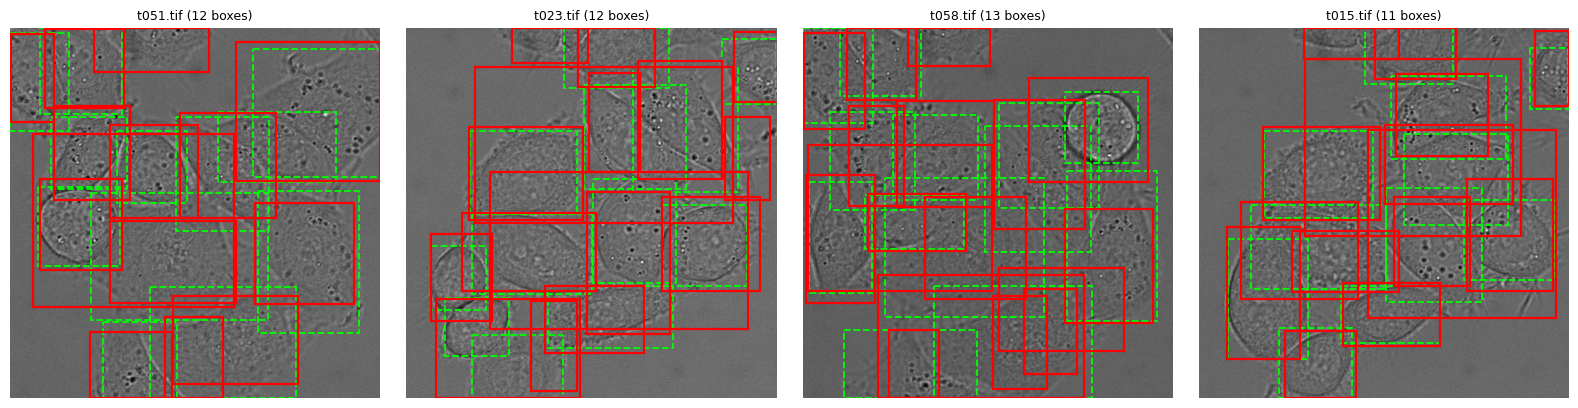

--- TRA box predictions ---


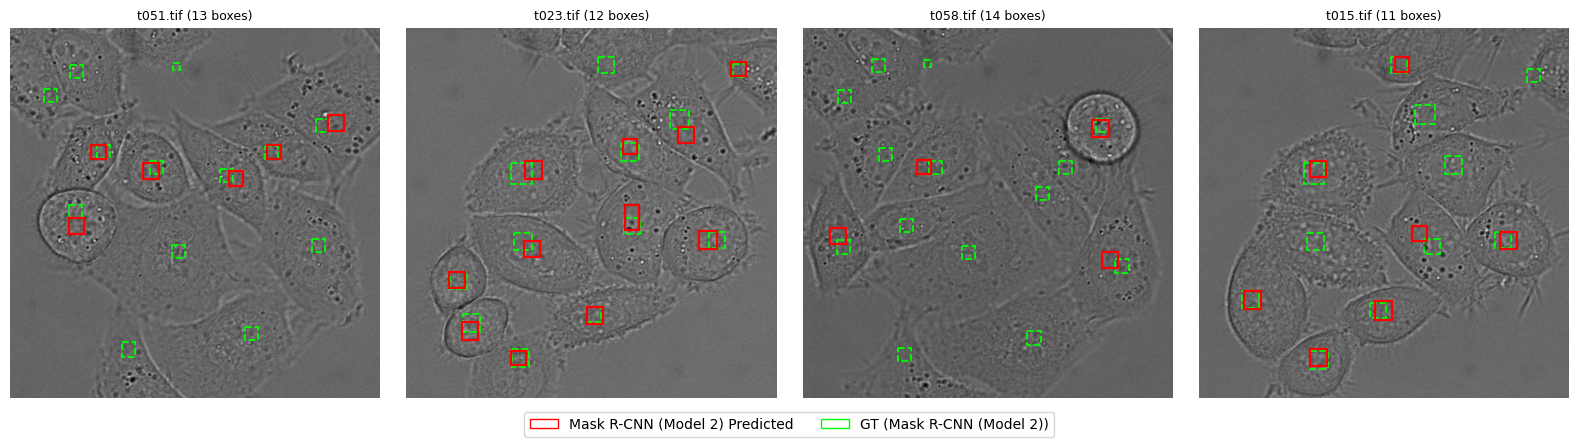

In [15]:
## ── Cell 8 : Prediction Helpers & GT vs Predicted box visualisation (SEG then TRA, stacked) ────

def predict_mask_rcnn_boxes(model, img2d, score_threshold=0.6, nms_iou_thresh=0.3, max_boxes=None):
    """Evaluates raw uncropped 2D frames and extracts bounding boxes from Mask R-CNN predictions,
    with a tighter NMS pass to kill overlapping duplicate detections."""
    model.eval()
    with torch.no_grad():
        img2d = img2d.astype(np.float32)
        img = (img2d - img2d.min()) / (np.ptp(img2d) + 1e-8)
        img_tensor = torch.tensor(img).float().unsqueeze(0).repeat(3, 1, 1).to(DEVICE)

        predictions = model([img_tensor])
        pred_boxes  = predictions[0]['boxes']
        pred_scores = predictions[0]['scores']

        # Step 1: confidence filter
        keep_score = pred_scores >= score_threshold
        pred_boxes, pred_scores = pred_boxes[keep_score], pred_scores[keep_score]

        # Step 2: stricter NMS to remove near-duplicate overlapping boxes
        from torchvision.ops import nms
        keep_nms = nms(pred_boxes, pred_scores, iou_threshold=nms_iou_thresh)
        pred_boxes = pred_boxes[keep_nms]

        # Step 3 (optional): cap to top-N boxes by score
        if max_boxes is not None and len(pred_boxes) > max_boxes:
            pred_boxes = pred_boxes[:max_boxes]

        return [box.astype(int).tolist() for box in pred_boxes.cpu().numpy()]

def predict_boxes_seg(img2d, n_boxes=None):
    return predict_mask_rcnn_boxes(detector_seg, img2d, score_threshold=0.6, nms_iou_thresh=0.3)

def predict_boxes_tra(img2d, n_boxes=None):
    return predict_mask_rcnn_boxes(detector_tra, img2d, score_threshold=0.6, nms_iou_thresh=0.3)


## ── GT vs Predicted box visualisation (SEG then TRA, stacked) ────
## Two separate figures, one per task, matching the reference figure style:
##   Figure 1 -- SEG (Model 1) : row of N_SAMPLES test images
##   [separator]
##   Figure 2 -- TRA (Model 2) : row of N_SAMPLES test images, with its own legend

N_SAMPLES = 4  # how many test images per row

def plot_box_row(pairs_subset, mask_index, predict_fn, task_label, model_label, show_legend=True):
    fig, axes = plt.subplots(1, N_SAMPLES, figsize=(4 * N_SAMPLES, 4))
    if N_SAMPLES == 1:
        axes = [axes]

    for col, (ax, entry) in enumerate(zip(axes, pairs_subset)):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        img     = tiff.imread(img_p).astype(np.float32)
        gt_mask = tiff.imread(mask_p).astype(np.int32)

        gt_boxes   = [box.tolist() for _, box in get_instance_boxes(gt_mask)]
        pred_boxes = predict_fn(img)

        ax.imshow(img, cmap='gray')

        for box in gt_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.3, edgecolor='lime',
                                      facecolor='none', linestyle='--')
            ax.add_patch(rect)

        for box in pred_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.6, edgecolor='red', facecolor='none')
            ax.add_patch(rect)

        ax.set_title(f'{os.path.basename(img_p)} ({len(gt_boxes)} boxes)', fontsize=9)
        ax.axis('off')

    if show_legend:
        legend_handles = [
            patches.Patch(edgecolor='red',  facecolor='none', label=f'{model_label} Predicted'),
            patches.Patch(edgecolor='lime', facecolor='none', label=f'GT ({model_label})'),
        ]
        fig.legend(handles=legend_handles, loc='upper center', ncol=2,
                   fontsize=10, bbox_to_anchor=(0.5, 0.02))

    plt.tight_layout()
    plt.show()


sample_seg = test_seg[:N_SAMPLES]
sample_tra = test_tra[:N_SAMPLES]

# ── SEG box predictions ────────────────────────────────────────────────
plot_box_row(sample_seg, mask_index=1, predict_fn=predict_boxes_seg,
             task_label='SEG', model_label='Mask R-CNN (Model 1)', show_legend=False)

# ── separator ─────────────────────────────────────────────────────────
print('--- TRA box predictions ---')

# ── TRA box predictions ────────────────────────────────────────────────
plot_box_row(sample_tra, mask_index=2, predict_fn=predict_boxes_tra,
             task_label='TRA', model_label='Mask R-CNN (Model 2)', show_legend=True)

## Cell 8b — Box predictions grid: SEG (top) vs TRA (bottom)

Same comparison as Cell 8, but as a multi-image grid and for **both** tasks -- GT boxes (dashed green) vs Mask R-CNN predicted boxes (red).

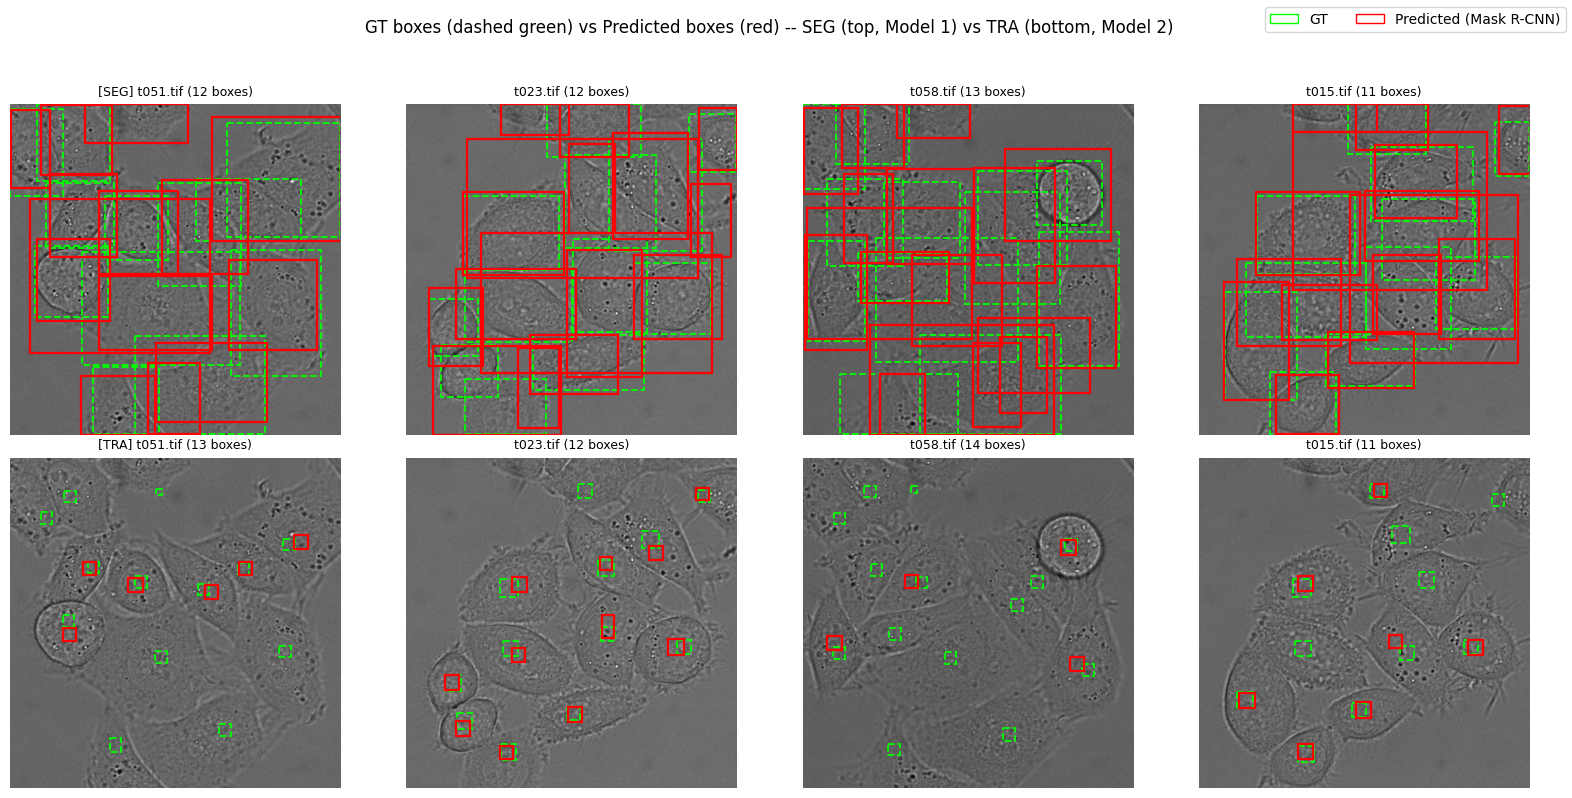

In [17]:
## ── Cell 8b : Multi-image grid -- GT vs Predicted boxes, SEG & TRA ───────
## Extends the single-image SEG-only plot above to a full grid covering
## BOTH tasks, matching the reference figure style.

N_SAMPLES = 4  # how many test images per row

def plot_box_row(pairs_subset, mask_index, predict_fn, task_label, ax_row):
    for col, (ax, entry) in enumerate(zip(ax_row, pairs_subset)):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        img     = tiff.imread(img_p).astype(np.float32)
        gt_mask = tiff.imread(mask_p).astype(np.int32)

        gt_boxes   = [box.tolist() for _, box in get_instance_boxes(gt_mask)]
        pred_boxes = predict_fn(img)

        ax.imshow(img, cmap='gray')

        for box in gt_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.3, edgecolor='lime',
                                      facecolor='none', linestyle='--')
            ax.add_patch(rect)

        for box in pred_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.6, edgecolor='red', facecolor='none')
            ax.add_patch(rect)

        prefix = f'[{task_label}] ' if col == 0 else ''
        ax.set_title(f'{prefix}{os.path.basename(img_p)} ({len(gt_boxes)} boxes)', fontsize=9)
        ax.axis('off')

sample_seg = test_seg[:N_SAMPLES]
sample_tra = test_tra[:N_SAMPLES]

fig, axes = plt.subplots(2, N_SAMPLES, figsize=(4*N_SAMPLES, 8))

plot_box_row(sample_seg, mask_index=1, predict_fn=predict_boxes_seg,
             task_label='SEG', ax_row=axes[0])
plot_box_row(sample_tra, mask_index=2, predict_fn=predict_boxes_tra,
             task_label='TRA', ax_row=axes[1])

legend_handles = [
    patches.Patch(edgecolor='lime', facecolor='none', label='GT'),
    patches.Patch(edgecolor='red',  facecolor='none', label='Predicted (Mask R-CNN)'),
]
fig.legend(handles=legend_handles, loc='upper right', ncol=2, fontsize=10)
fig.suptitle('GT boxes (dashed green) vs Predicted boxes (red) -- SEG (top, Model 1) vs TRA (bottom, Model 2)',
             fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


## Cell 9 — Inspect one test image per task

In [18]:
## ── Cell 9 : Inspect test images ────────────────────────────────────────
def inspect_test_image(entry, mask_index, task_label):
    img_p  = entry[0]
    mask_p = entry[mask_index]
    gt     = tiff.imread(mask_p).astype(np.int32)
    H, W   = gt.shape
    ids    = np.unique(gt); ids = ids[ids != 0]
    print(f'\n[{task_label}]  image={os.path.basename(img_p)}  size=({W},{H})  objects={len(ids)}')
    for oid in ids:
        b = bbox_from_mask((gt == oid).astype(np.uint8))
        if b is None: continue
        x1,y1,x2,y2 = b
        print(f'  ID={oid}  box={b}  W={round((x2-x1)/W*100,1)}%  H={round((y2-y1)/H*100,1)}%')

inspect_test_image(test_seg[0], mask_index=1, task_label='SEG')
inspect_test_image(test_tra[0], mask_index=2, task_label='TRA')


[SEG]  image=t051.tif  size=(512,512)  objects=12
  ID=2  box=[56, 122, 161, 222]  W=20.5%  H=19.5%
  ID=4  box=[147, 142, 245, 241]  W=19.1%  H=19.3%
  ID=5  box=[38, 220, 152, 329]  W=22.3%  H=21.3%
  ID=9  box=[111, 228, 356, 403]  W=47.9%  H=34.2%
  ID=16  box=[288, 116, 450, 212]  W=31.6%  H=18.8%
  ID=17  box=[229, 122, 358, 281]  W=25.2%  H=31.1%
  ID=18  box=[336, 28, 511, 206]  W=34.2%  H=34.8%
  ID=22  box=[342, 225, 482, 421]  W=27.3%  H=38.3%
  ID=23  box=[193, 358, 395, 511]  W=39.5%  H=29.9%
  ID=26  box=[128, 406, 230, 511]  W=19.9%  H=20.5%
  ID=44  box=[41, 0, 154, 118]  W=22.1%  H=23.0%
  ID=45  box=[0, 7, 81, 142]  W=15.8%  H=26.4%

[TRA]  image=t051.tif  size=(512,512)  objects=13
  ID=2  box=[120, 161, 138, 179]  W=3.5%  H=3.5%
  ID=4  box=[193, 183, 211, 202]  W=3.5%  H=3.7%
  ID=5  box=[81, 244, 99, 262]  W=3.5%  H=3.5%
  ID=9  box=[224, 300, 242, 318]  W=3.5%  H=3.5%
  ID=16  box=[352, 163, 370, 181]  W=3.5%  H=3.5%
  ID=17  box=[290, 195, 308, 213]  W=3.5%  H=

## Cell 10 — Baseline evaluation (pretrained MedSAM, no fine-tuning)

In [19]:
## ── Cell 10 : Baseline evaluation ───────────────────────────────────────
import inspect

def evaluate(model, dataset, predict_fn=None, mask_index=1, verbose=True):
    """
    predict_fn=None  → use perfect GT boxes (upper-bound baseline)
    predict_fn=fn    → use Faster R-CNN predicted boxes (realistic scenario)
    mask_index       → 1 for SEG, 2 for TRA
    """
    rows = []
    for entry in tqdm(dataset, desc='eval'):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        if mask_p is None: continue

        img     = tiff.imread(img_p)
        gt_full = tiff.imread(mask_p).astype(np.int32)
        H, W    = gt_full.shape
        gt      = (gt_full > 0).astype(np.uint8)

        if predict_fn is not None:
            # Safely handle prediction parameters dynamically for Faster R-CNN
            sig = inspect.signature(predict_fn)
            if 'n_boxes' in sig.parameters:
                pred_boxes = predict_fn(img, n_boxes=5)
            else:
                pred_boxes = predict_fn(img)
        else:
            ids = np.unique(gt_full); ids = ids[ids != 0]
            pred_boxes = [b for b in
                          [bbox_from_mask((gt_full == oid).astype(np.uint8)) for oid in ids]
                          if b is not None]
        if not pred_boxes: continue

        final = np.zeros((H, W), dtype=np.uint8)
        for box in pred_boxes:
            pm = medsam_predict(model, img, box)
            if pm.shape != (H, W):
                pm = cv2.resize(pm, (W, H), interpolation=cv2.INTER_NEAREST)
            final = np.maximum(final, (pm > 0.5).astype(np.uint8))

        d, i, p, r = metrics(final, gt)
        rows.append({'image': os.path.basename(img_p),
                     'dice': round(d,3), 'iou': round(i,3),
                     'prec': round(p,3), 'rec': round(r,3)})

    res = pd.DataFrame(rows)
    if verbose and len(res):
        print(res.to_string(index=False))
        print(f'\nMean Dice: {res.dice.mean():.3f} ± {res.dice.std():.3f}'
              f' | Mean IoU: {res.iou.mean():.3f}')
    return (res.dice.mean(), res.iou.mean(),
            res.prec.mean(), res.rec.mean()) if len(res) else (0,0,0,0)


# ── SEG baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — SEG GT boxes (baseline) ===')
base_d_seg, base_i_seg, _, _ = evaluate(medsam, test_seg,
                                         predict_fn=None, mask_index=1)

# ── TRA baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — TRA GT boxes (baseline) ===')
base_d_tra, base_i_tra, _, _ = evaluate(medsam, test_tra,
                                         predict_fn=None, mask_index=2)


=== Pretrained MedSAM — SEG GT boxes (baseline) ===


eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.908 0.831 0.931 0.886
t023.tif 0.901 0.820 0.956 0.853
t058.tif 0.897 0.812 0.918 0.876
t015.tif 0.905 0.826 0.942 0.870
t060.tif 0.894 0.808 0.910 0.879
t025.tif 0.933 0.875 0.969 0.899
t053.tif 0.901 0.819 0.922 0.880
t031.tif 0.897 0.814 0.975 0.831
t016.tif 0.912 0.839 0.941 0.885
t044.tif 0.923 0.856 0.941 0.905
t072.tif 0.898 0.816 0.938 0.862
t034.tif 0.901 0.820 0.956 0.851
t030.tif 0.899 0.817 0.953 0.851
t058.tif 0.899 0.817 0.905 0.894
t035.tif 0.910 0.834 0.956 0.867
t077.tif 0.913 0.839 0.918 0.907
t049.tif 0.906 0.827 0.907 0.904
t006.tif 0.920 0.852 0.953 0.890
t018.tif 0.912 0.837 0.960 0.868
t055.tif 0.928 0.866 0.953 0.905
t071.tif 0.910 0.835 0.932 0.889
t041.tif 0.905 0.827 0.941 0.872
t026.tif 0.913 0.840 0.941 0.887
t022.tif 0.906 0.828 0.956 0.861
t019.tif 0.887 0.797 0.936 0.843
t064.tif 0.911 0.836 0.930 0.892
t047.tif 0.901 0.821 0.914 0.889
t029.tif 0.935 0.878 0.944 0.926
t056.tif 0.911 0.837 0.939 0.885
t014.tif 0

eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.593 0.421 0.942 0.433
t023.tif 0.526 0.357 0.985 0.359
t058.tif 0.530 0.360 0.952 0.367
t015.tif 0.571 0.400 0.968 0.405
t060.tif 0.596 0.425 0.970 0.430
t025.tif 0.449 0.289 0.937 0.295
t053.tif 0.616 0.445 0.938 0.458
t031.tif 0.532 0.363 0.958 0.369
t016.tif 0.449 0.290 0.937 0.296
t044.tif 0.557 0.386 0.985 0.388
t072.tif 0.637 0.468 0.925 0.486
t034.tif 0.487 0.322 0.951 0.327
t030.tif 0.556 0.385 0.963 0.391
t058.tif 0.545 0.375 0.976 0.379
t035.tif 0.582 0.410 0.962 0.417
t077.tif 0.541 0.371 0.945 0.379
t049.tif 0.524 0.355 0.977 0.358
t006.tif 0.422 0.267 0.958 0.270
t018.tif 0.551 0.380 0.933 0.391
t055.tif 0.623 0.453 0.916 0.472
t071.tif 0.532 0.363 0.949 0.370
t041.tif 0.608 0.437 0.978 0.442
t026.tif 0.462 0.300 0.869 0.315
t022.tif 0.477 0.313 0.991 0.314
t019.tif 0.551 0.380 0.974 0.384
t064.tif 0.566 0.395 0.964 0.401
t047.tif 0.550 0.380 0.975 0.383
t029.tif 0.506 0.339 0.894 0.353
t056.tif 0.601 0.430 0.972 0.435
t014.tif 0

## Cell 11 — Dataset class & fine-tune function

In [20]:
## ── Cell 11 : Dataset & fine-tune ───────────────────────────────────────
def collate(batch): return batch[0]   # batch_size = 1

class HeLaDataset(Dataset):
    def __init__(self, pairs, predict_fn=None, mask_index=1):
        """
        predict_fn=None  → GT boxes  (Exp B)
        predict_fn=fn    → ResNet boxes (Exp A)
        mask_index       → 1 = SEG, 2 = TRA
        """
        self.pairs      = pairs
        self.predict_fn = predict_fn
        self.mask_index = mask_index

    def __len__(self): return len(self.pairs)

    def __getitem__(self, i):
        entry  = self.pairs[i]
        img_p  = entry[0]
        mask_p = entry[self.mask_index]

        img = tiff.imread(img_p)
        H, W = img.shape

        if mask_p is None:                              # fallback: black mask
            gt    = np.zeros((H, W), dtype=np.uint8)
            boxes = np.array([[0, 0, W-1, H-1]], dtype=np.float32)
        else:
            gt_full = tiff.imread(mask_p).astype(np.int32)
            gt      = (gt_full > 0).astype(np.uint8)
            if self.predict_fn is not None:
                boxes = self.predict_fn(img, n_boxes=5)
            else:
                ids   = np.unique(gt_full); ids = ids[ids != 0]
                boxes = [b for b in
                         [bbox_from_mask((gt_full==oid).astype(np.uint8)) for oid in ids]
                         if b is not None]
            if not boxes:
                boxes = [[0, 0, W-1, H-1]]

        rgb   = transform.apply_image(preprocess_image(img).astype(np.uint8))
        boxes = transform.apply_boxes(np.array(boxes, dtype=np.float32), (H, W))
        return (
            torch.as_tensor(rgb).permute(2, 0, 1).float(),
            torch.tensor(gt).unsqueeze(0).float(),
            torch.tensor(boxes).float(),
            (H, W)
        )


dice_loss = DiceLoss(sigmoid=True)
bce       = torch.nn.BCEWithLogitsLoss()
scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


def forward_logits(model, img_t, boxes, hw):
    H, W   = hw
    img_t  = img_t.to(DEVICE)
    boxes  = boxes.to(DEVICE)
    in_t   = model.preprocess(img_t.unsqueeze(0))
    with torch.no_grad():
        emb = model.image_encoder(in_t)
    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=boxes, masks=None)
    low_res, _ = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    logits = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    return logits.amax(dim=0, keepdim=True)


def fine_tune(model, train_dl, val_dl, epochs=20, lr=1e-4,
              ckpt_name='model.pth', tag='FT', mask_index=1):
    for p in model.image_encoder.parameters():  p.requires_grad = False
    for p in model.prompt_encoder.parameters(): p.requires_grad = False
    for p in model.mask_decoder.parameters():   p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    best_dice = -1

    for ep in range(epochs):
        model.train(); total_loss = 0
        for img_t, gt, boxes, hw in tqdm(train_dl, desc=f'{tag} ep{ep}'):
            gt = gt.unsqueeze(0).to(DEVICE)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
                logits = forward_logits(model, img_t, boxes, hw)
                loss   = dice_loss(logits, gt) + bce(logits, gt)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            total_loss += loss.item()
        scheduler.step()

        model.eval(); vd = vi = n = 0
        with torch.no_grad():
            for img_t, gt, boxes, hw in val_dl:
                logits = forward_logits(model, img_t, boxes, hw)
                pred   = (torch.sigmoid(logits)[0,0].cpu().numpy() > 0.5).astype(np.uint8)
                d, i, _, _ = metrics(pred, gt[0].numpy())
                vd += d; vi += i; n += 1
        vd /= n; vi /= n
        print(f'{tag} ep{ep}: loss={total_loss/len(train_dl):.4f} | val_dice={vd:.4f}')
        if vd > best_dice:
            best_dice = vd
            torch.save(model.state_dict(), ckpt_name)
            print('  ✅ saved best model')

print('Dataset class and fine_tune() ready.')

Dataset class and fine_tune() ready.


/tmp/ipykernel_420/945023224.py:53: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


In [21]:
## ── Cell 12 : Fine-tune -- 2 experiments (Exp A & Exp B) ──────────────────
## Checkpoints are saved to CKPT_DIR (Google Drive, set up in Cell 1b) so
## they survive a runtime disconnect. Per-experiment epoch budget instead of
## one flat number: SEG tasks (and A-TRA) converge fast, but B-TRA (Mask
## R-CNN boxes, TRA masks) was still improving at epoch 20 in the original
## run -- giving it more epochs than the others.

FT_EPOCHS = {
    'A-SEG': 5,
    'A-TRA': 5,
    'B-SEG': 5,
    'B-TRA': 12,   # slow to converge -- worth the extra time
}

def get_or_finetune(train_pairs, val_pairs, predict_fn, mask_index, ckpt_name, tag):
    path = ckpt_path(ckpt_name)   # routed through Drive-backed CKPT_DIR (Cell 1b)
    epochs = FT_EPOCHS[tag]

    if os.path.exists(path):
        print(f'✅ Found {path} -- loading (skipping fine-tune).')
        model = load_medsam()
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        model.to(DEVICE); model.eval()
        return model

    print(f'⏳ No checkpoint for {tag} -- fine-tuning {epochs} epochs...')
    model = load_medsam()
    if DEVICE == 'cuda': torch.cuda.empty_cache()

    dl_train = DataLoader(HeLaDataset(train_pairs, predict_fn=predict_fn, mask_index=mask_index),
                           batch_size=1, shuffle=True, collate_fn=collate, num_workers=0,
                           pin_memory=(DEVICE=='cuda'))
    dl_val   = DataLoader(HeLaDataset(val_pairs,   predict_fn=predict_fn, mask_index=mask_index),
                           batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                           pin_memory=(DEVICE=='cuda'))

    fine_tune(model, dl_train, dl_val, epochs=epochs, lr=1e-4, ckpt_name=path, tag=tag)
    model.load_state_dict(torch.load(path, map_location=DEVICE))  # reload best-val checkpoint
    model.to(DEVICE); model.eval()
    return model


# =========================================================================
# ─── EXPERIMENT A : Train on GT boxes / Test on Mask R-CNN ──────────────
# =========================================================================
print('\n====== Exp A-SEG : GT boxes, SEG masks ======')
medsam_expA_seg = get_or_finetune(train_seg, val_seg, predict_fn=None, mask_index=1,
                                   ckpt_name='medsam_seg_gtbox.pth', tag='A-SEG')

print('\n====== Exp A-TRA : GT boxes, TRA masks ======')
medsam_expA_tra = get_or_finetune(train_tra, val_tra, predict_fn=None, mask_index=2,
                                   ckpt_name='medsam_tra_gtbox.pth', tag='A-TRA')

# =========================================================================
# ─── EXPERIMENT B : Train on Mask R-CNN boxes / Test on Mask R-CNN ─────
# =========================================================================
print('\n====== Exp B-SEG : Mask R-CNN boxes, SEG masks ======')
medsam_expB_seg = get_or_finetune(train_seg, val_seg, predict_fn=predict_boxes_seg, mask_index=1,
                                   ckpt_name='medsam_seg_predbox.pth', tag='B-SEG')

print('\n====== Exp B-TRA : Mask R-CNN boxes, TRA masks ======')
medsam_expB_tra = get_or_finetune(train_tra, val_tra, predict_fn=predict_boxes_tra, mask_index=2,
                                   ckpt_name='medsam_tra_predbox.pth', tag='B-TRA')



====== Exp A-SEG : GT boxes, SEG masks ======
⏳ No checkpoint for A-SEG -- fine-tuning 5 epochs...


A-SEG ep0:   0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_420/945023224.py:91: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


A-SEG ep0: loss=0.2485 | val_dice=0.9408
  ✅ saved best model


A-SEG ep1:   0%|          | 0/100 [00:00<?, ?it/s]

A-SEG ep1: loss=0.2051 | val_dice=0.9462
  ✅ saved best model


... (46 outputs left out)

B-TRA ep10:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep10: loss=0.4258 | val_dice=0.4015


B-TRA ep11:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep11: loss=0.4219 | val_dice=0.4028


In [22]:
import os
files = ['medsam_seg_predbox.pth', 'medsam_seg_gtbox.pth', 'medsam_tra_predbox.pth', 'medsam_tra_gtbox.pth']
for f in files:
    print(f, '→', 'FOUND ✅' if os.path.exists(ckpt_path(f)) else 'MISSING ❌')


medsam_seg_predbox.pth → FOUND ✅
medsam_seg_gtbox.pth → FOUND ✅
medsam_tra_predbox.pth → FOUND ✅
medsam_tra_gtbox.pth → FOUND ✅


## Cell 13 — Final evaluation & comparison table

In [23]:
## ── Cell 13 : Final evaluation & comparison table (SEG/TRA/BOTH aware) ────

results = {}

if run_seg:
    # Exp A : trained on GT boxes / tested with Mask R-CNN boxes
    medsam_expA_seg = load_medsam()
    medsam_expA_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_gtbox.pth'), map_location=DEVICE))
    medsam_expA_seg.to(DEVICE); medsam_expA_seg.eval()

    # Exp B : trained on Mask R-CNN boxes / tested with Mask R-CNN boxes
    medsam_expB_seg = load_medsam()
    medsam_expB_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_predbox.pth'), map_location=DEVICE))
    medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

    print('Evaluating — SEG task (train GT / test Mask R-CNN) ...')
    aB_seg_d, aB_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

    print('Evaluating — SEG task (train Mask R-CNN / test Mask R-CNN) ...')
    bB_seg_d, bB_seg_i, _, _ = evaluate(medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

    results['SEG'] = (aB_seg_d, aB_seg_i, bB_seg_d, bB_seg_i)

if run_tra:
    # Exp A : trained on GT boxes / tested with Mask R-CNN boxes
    medsam_expA_tra = load_medsam()
    medsam_expA_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_gtbox.pth'), map_location=DEVICE))
    medsam_expA_tra.to(DEVICE); medsam_expA_tra.eval()

    # Exp B : trained on Mask R-CNN boxes / tested with Mask R-CNN boxes
    medsam_expB_tra = load_medsam()
    medsam_expB_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_predbox.pth'), map_location=DEVICE))
    medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

    print('Evaluating — TRA task (train GT / test Mask R-CNN) ...')
    aB_tra_d, aB_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)

    print('Evaluating — TRA task (train Mask R-CNN / test Mask R-CNN) ...')
    bB_tra_d, bB_tra_i, _, _ = evaluate(medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)

    results['TRA'] = (aB_tra_d, aB_tra_i, bB_tra_d, bB_tra_i)


# ── Build comparison table from whichever task(s) were run ────────────────
rows = []
for task, (a_d, a_i, b_d, b_i) in results.items():
    rows.append({'Task': task, 'Model': 'Exp A (train GT / test Mask R-CNN)', 'Dice': round(a_d, 3), 'IoU': round(a_i, 3)})
    rows.append({'Task': task, 'Model': 'Exp B (train Mask R-CNN / test Mask R-CNN)', 'Dice': round(b_d, 3), 'IoU': round(b_i, 3)})

cmp_all = pd.DataFrame(rows)

print(f'\n=== Exp A vs Exp B Comparison ({TASK_MODE}, tested on Mask R-CNN boxes) ===')
print(cmp_all.to_string(index=False))

Evaluating — SEG task (train GT / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (train GT / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — SEG task (train Mask R-CNN / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (train Mask R-CNN / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


=== Exp A vs Exp B Comparison (both tested on Mask R-CNN boxes) ===
Task                                      Model  Dice   IoU
 SEG         Exp A (train GT / test Mask R-CNN) 0.871 0.772
 TRA         Exp A (train GT / test Mask R-CNN) 0.394 0.252
 SEG Exp B (train Mask R-CNN / test Mask R-CNN) 0.909 0.834
 TRA Exp B (train Mask R-CNN / test Mask R-CNN) 0.419 0.272


## Cell 14 — Qualitative visualisation

--- SEG : before vs after fine-tuning (Exp B) ---


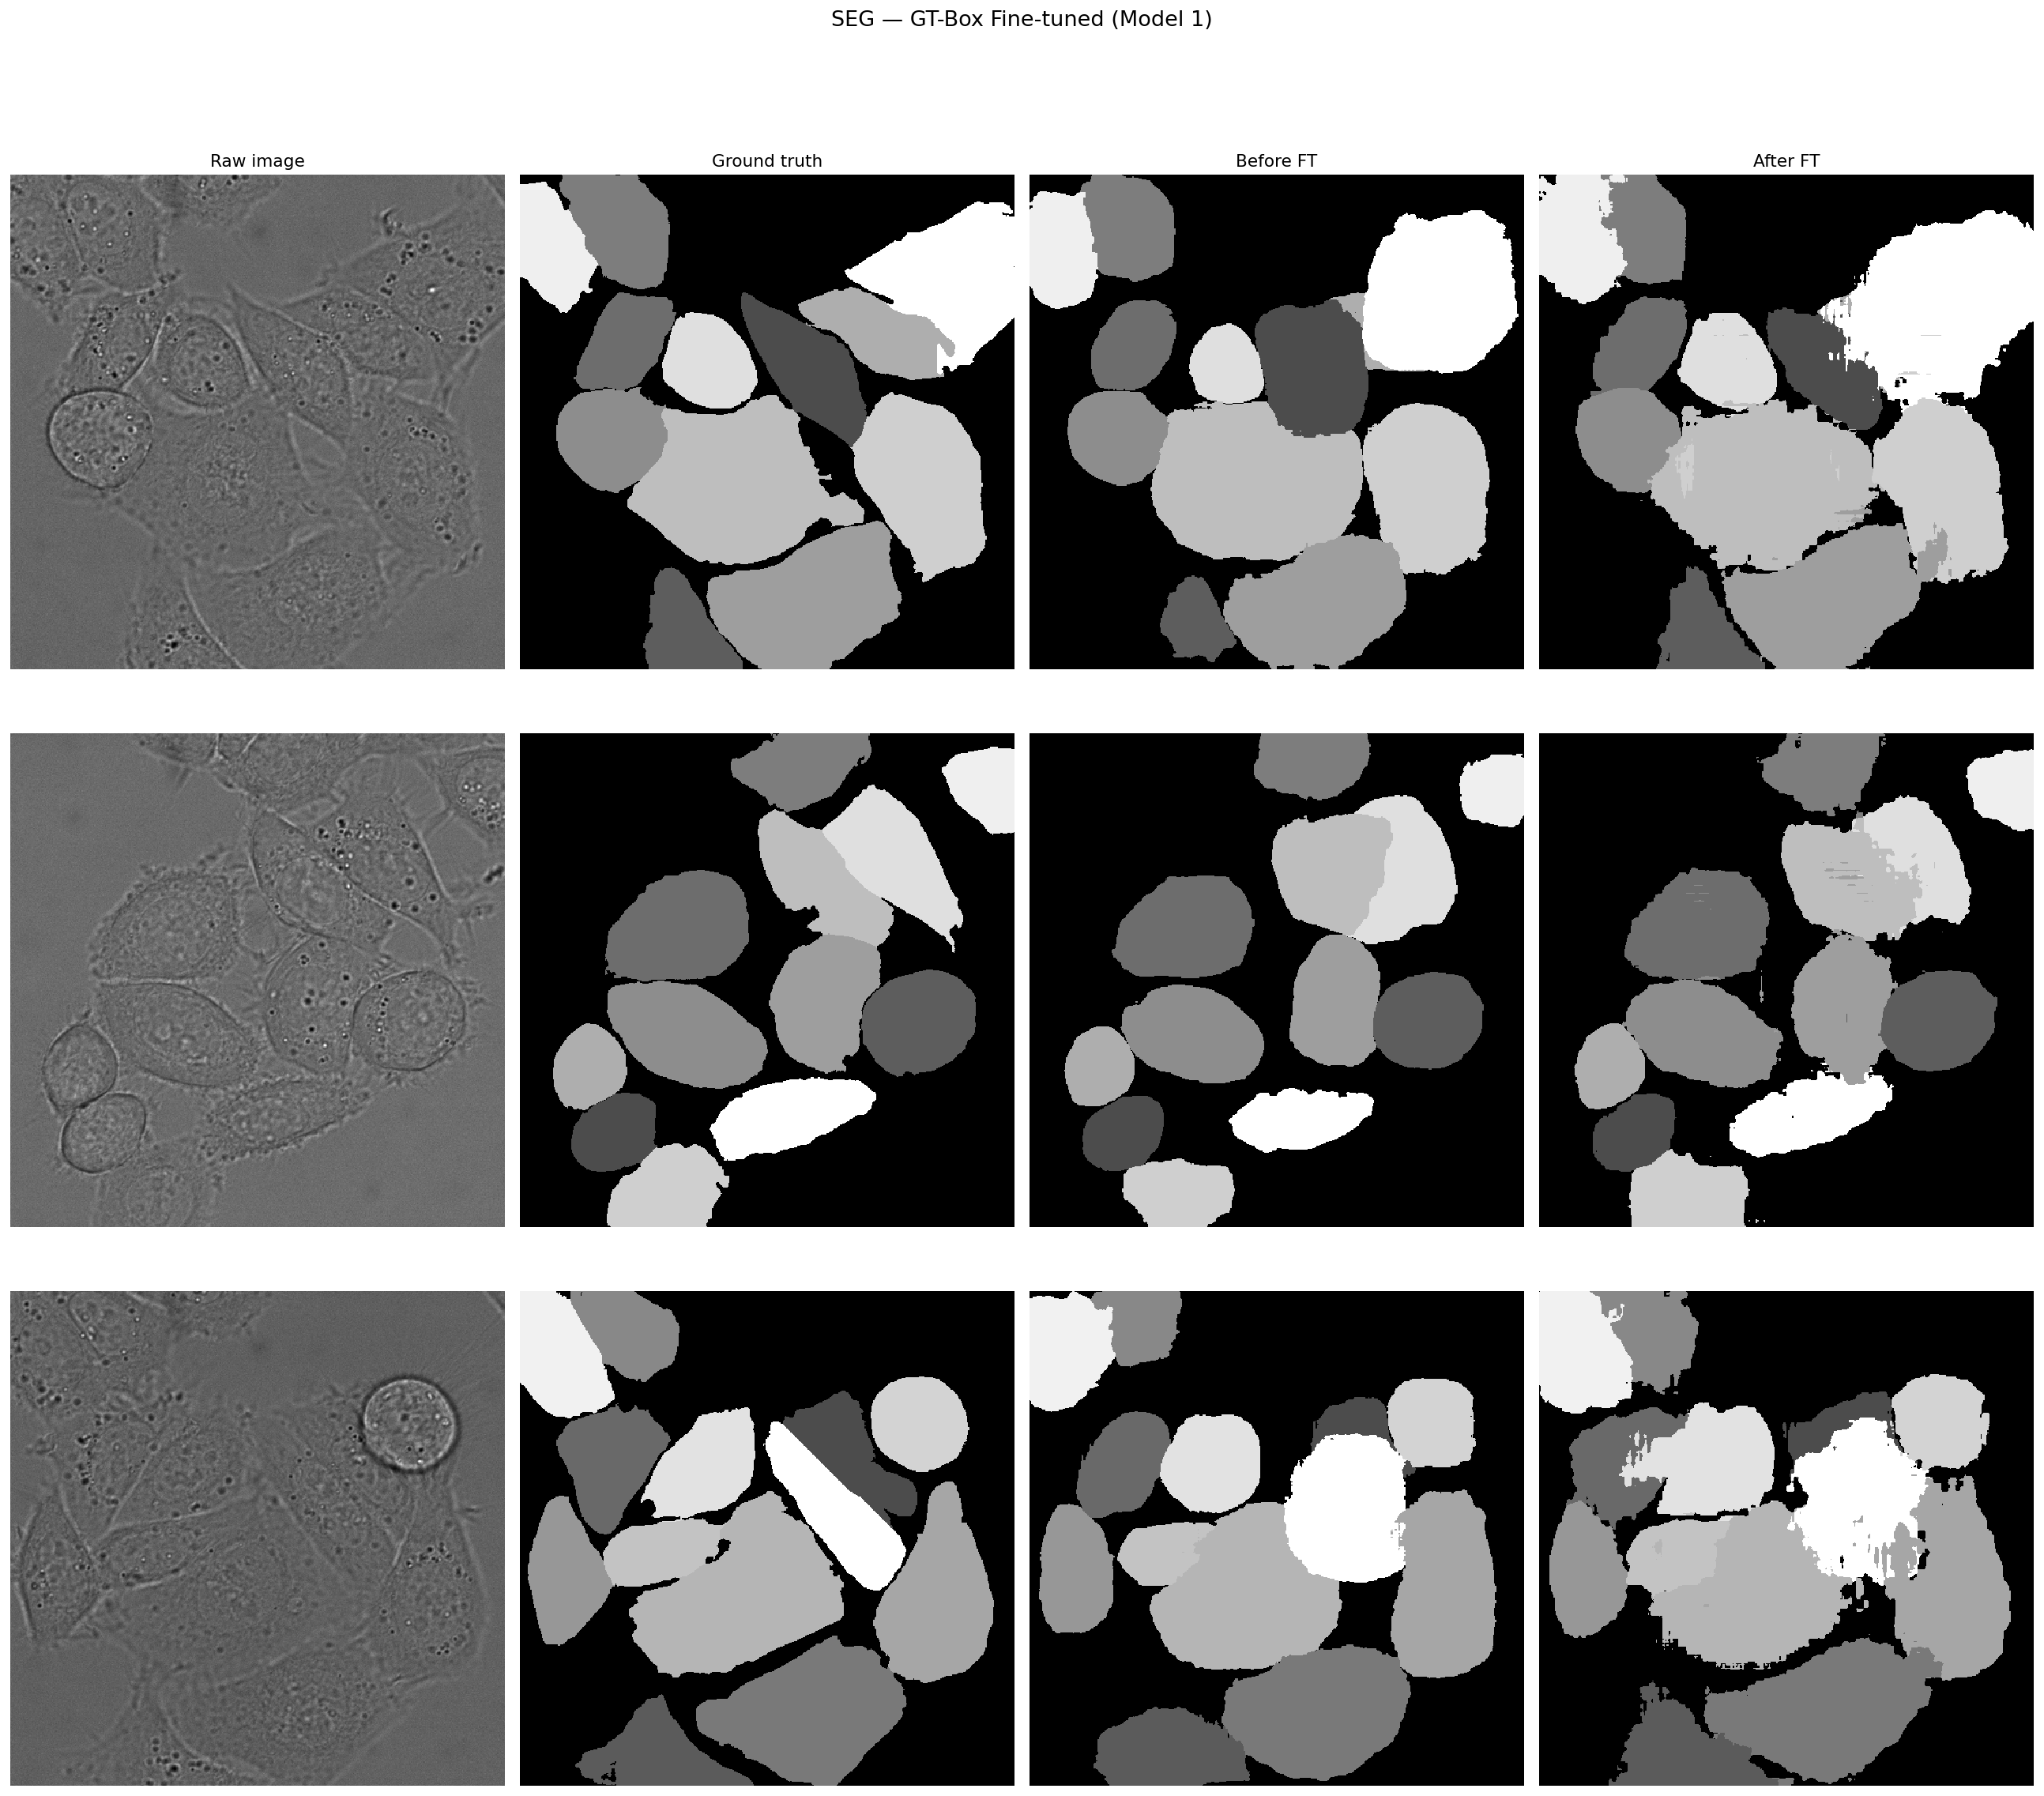

--- TRA : before vs after fine-tuning (Exp B) ---


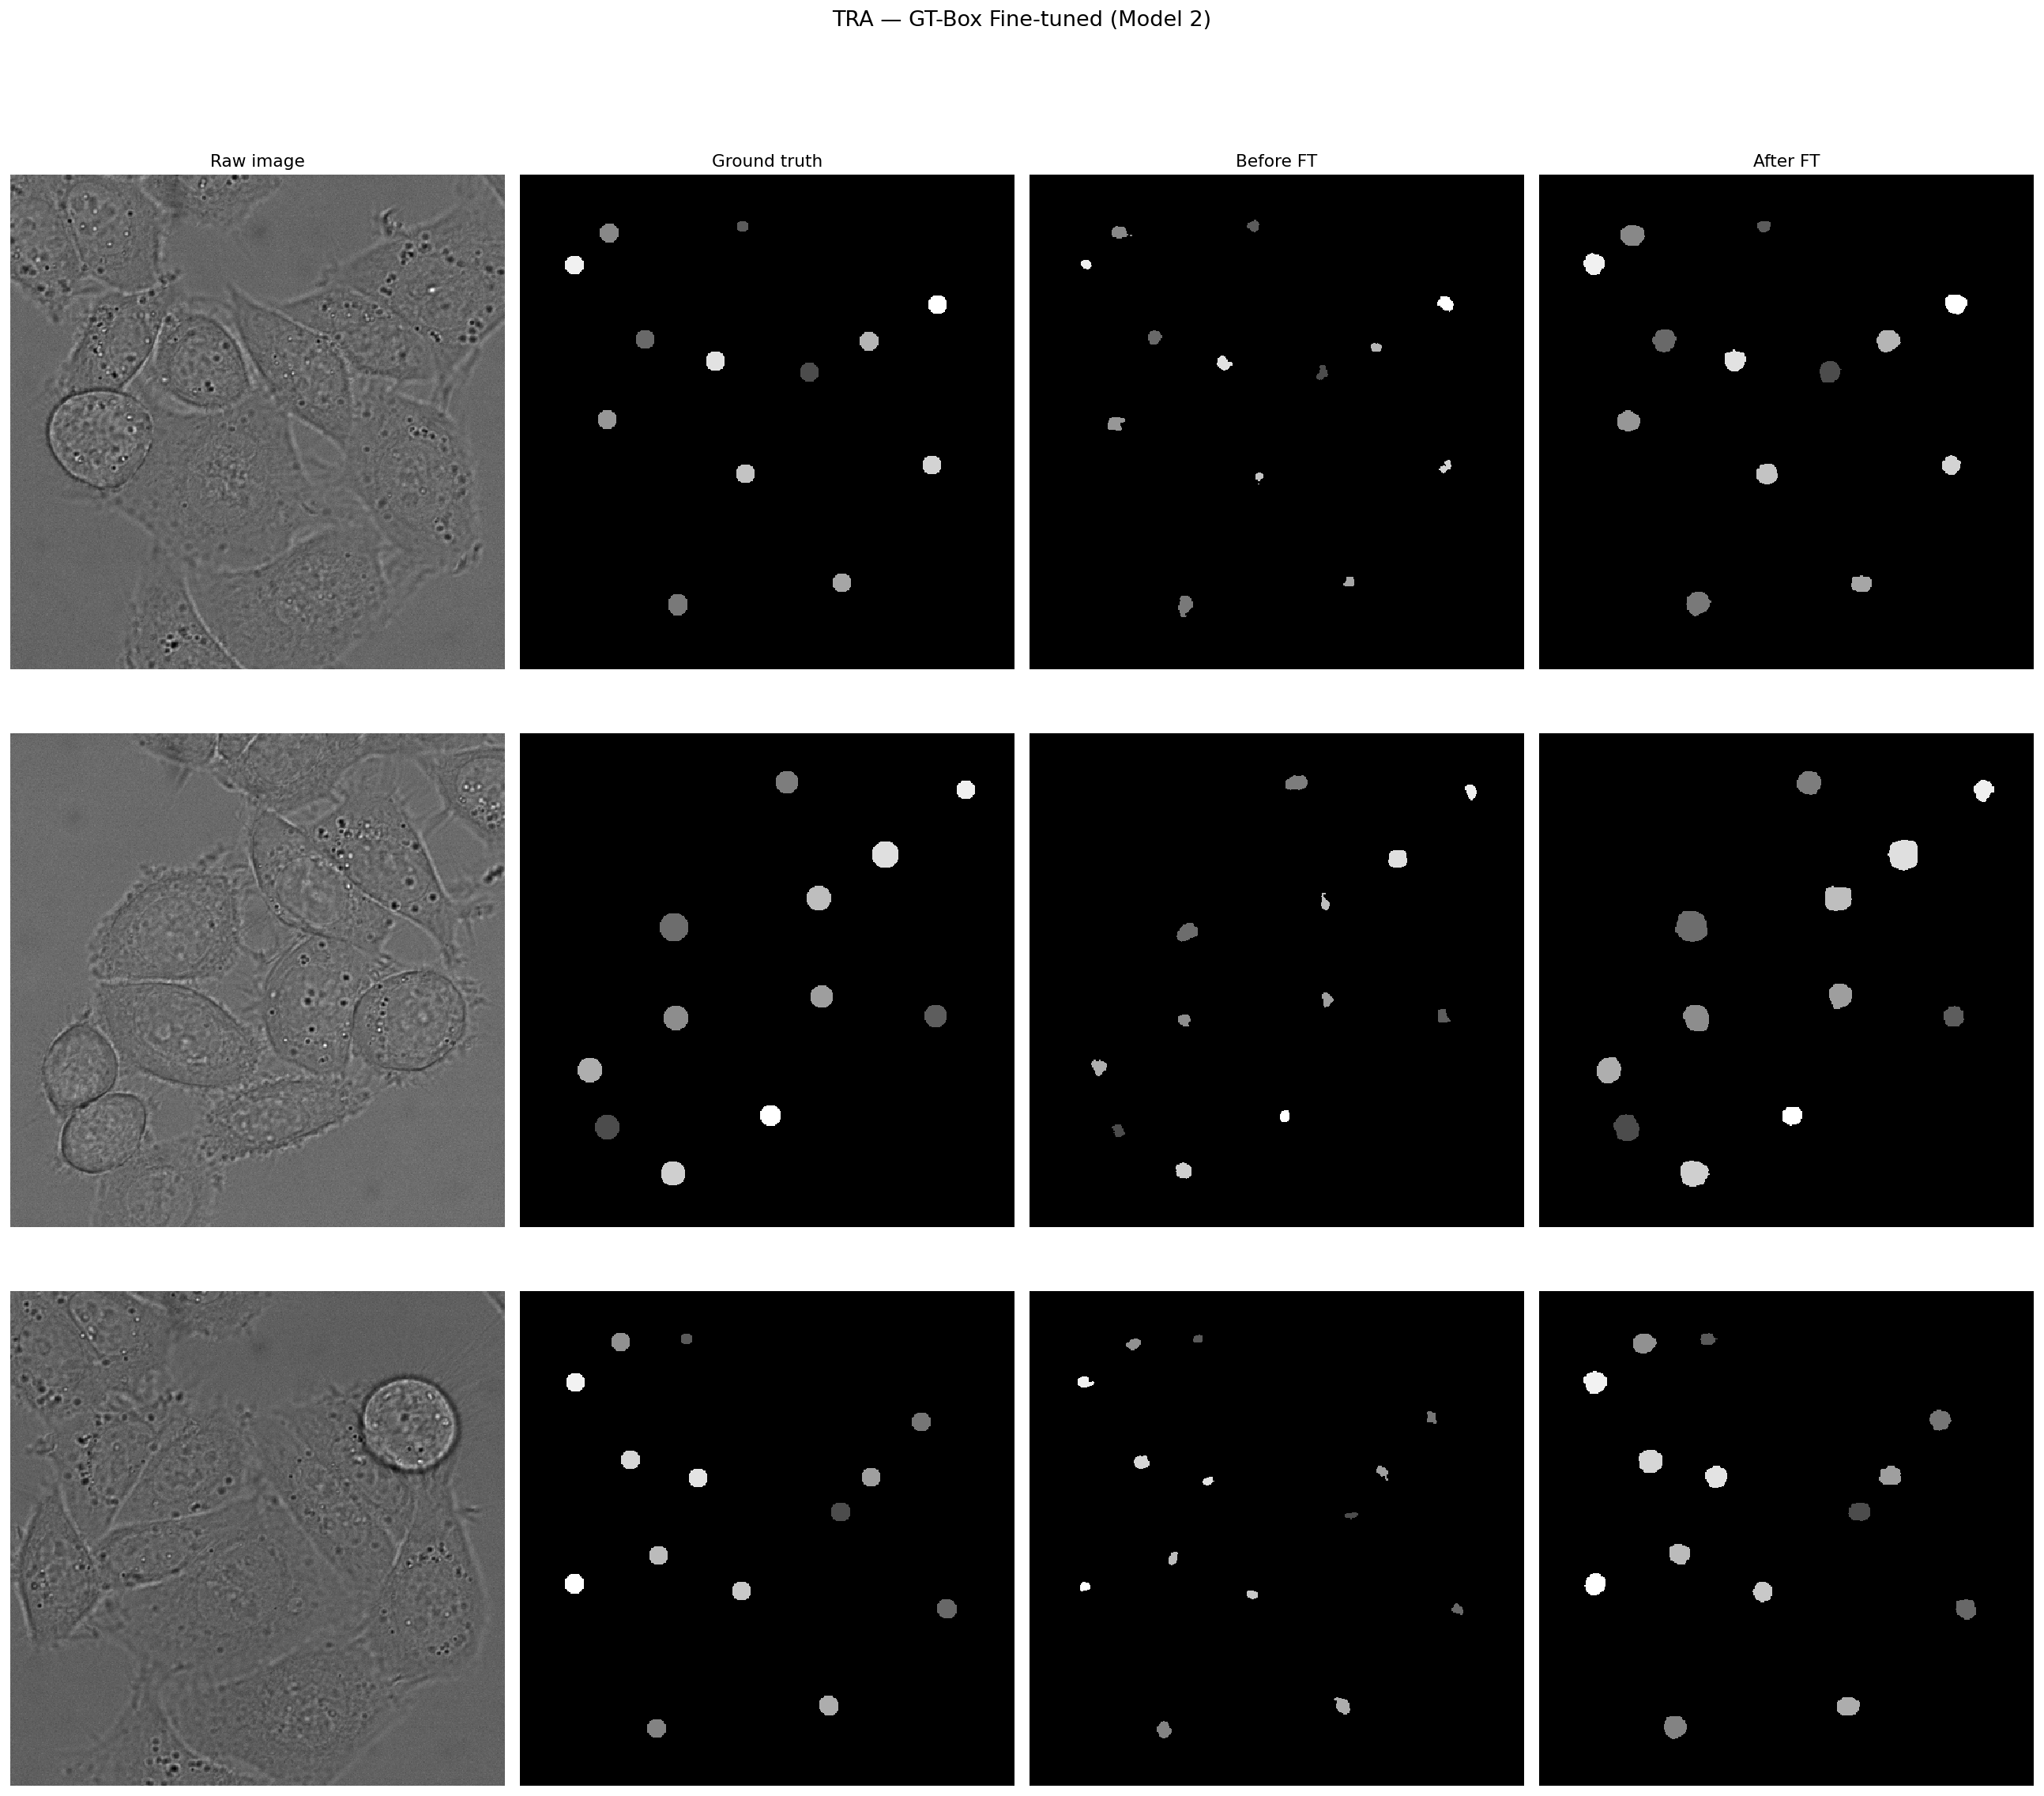

In [24]:
## ── Cell 14 : Qualitative visualisation ─────────────────────────────────

def instance_to_sharp_grayscale(inst_map):
    inst_map = inst_map.astype(np.int32)
    ids      = np.unique(inst_map); ids = ids[ids != 0]
    out      = np.zeros(inst_map.shape, dtype=float)
    if len(ids) == 0: return out
    levels   = np.linspace(1.0, 0.3, len(ids))
    np.random.default_rng(0).shuffle(levels)
    for uid, g in zip(ids, levels):
        out[inst_map == uid] = g
    return out


def boxes_to_instance_grayscale(model, img2d, boxes):
    """Run MedSAM per box and assign each a unique shade — avoids cell merging in display."""
    H, W     = img2d.shape
    inst_map = np.zeros((H, W), dtype=np.int32)
    for nxt, box in enumerate(boxes, 1):
        m = medsam_predict(model, img2d, box) > 0
        inst_map[m] = nxt
    return instance_to_sharp_grayscale(inst_map)


def show_final(samples, model_before, model_after, mask_index, title):
    cols = ['Raw image', 'Ground truth', 'Before FT', 'After FT']
    fig, ax = plt.subplots(len(samples), 4,
                           figsize=(20, 6*len(samples)), dpi=130)
    if len(samples) == 1: ax = [ax]

    for r, entry in enumerate(samples):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        img    = tiff.imread(img_p)
        gt_inst = tiff.imread(mask_p).astype(np.int32)
        gt_disp = instance_to_sharp_grayscale(gt_inst)

        ids   = np.unique(gt_inst); ids = ids[ids != 0]
        boxes = [b for b in [bbox_from_mask((gt_inst==oid).astype(np.uint8)) for oid in ids] if b]
        if not boxes:
            H, W = img.shape; boxes = [[0, 0, W-1, H-1]]

        pre_disp  = boxes_to_instance_grayscale(model_before, img, boxes)
        post_disp = boxes_to_instance_grayscale(model_after,  img, boxes)

        for c, (im, cmap_kw) in enumerate(
            [(img,      {'cmap':'gray'}),
             (gt_disp,  {'cmap':'gray','vmin':0,'vmax':1}),
             (pre_disp, {'cmap':'gray','vmin':0,'vmax':1}),
             (post_disp,{'cmap':'gray','vmin':0,'vmax':1})]):
            a = ax[r][c]
            a.imshow(im, interpolation='none', **cmap_kw)
            a.axis('off')
            if r == 0: a.set_title(cols[c], fontsize=12)

    plt.suptitle(title, fontsize=15, y=1.0)
    plt.subplots_adjust(wspace=0.02, hspace=0.05)
    plt.tight_layout(rect=[0,0,1,0.97]); plt.show()


# ── SEG : pretrained vs Exp B (GT boxes, best scenario) ──────────────────
print('--- SEG : before vs after fine-tuning (Exp B) ---')
show_final(test_seg[:3], medsam, medsam_expB_seg, mask_index=1,
           title='SEG — GT-Box Fine-tuned (Model 1)')

# ── TRA : pretrained vs Exp B (GT boxes, best scenario) ──────────────────
print('--- TRA : before vs after fine-tuning (Exp B) ---')
show_final(test_tra[:3], medsam, medsam_expB_tra, mask_index=2,
           title='TRA — GT-Box Fine-tuned (Model 2)')

In [25]:
## ── New Cell : Exp A (instructed) — train on GT boxes, test on ResNet boxes ──

# Reuse the already-trained GT-box checkpoints (no retraining needed)
medsam_expB_seg = load_medsam()
medsam_expB_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_gtbox.pth'), map_location=DEVICE))
medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

medsam_expB_tra = load_medsam()
medsam_expB_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_gtbox.pth'), map_location=DEVICE))
medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

# Evaluate the GT-trained model, but feed it ResNet-predicted boxes at test time
print('Evaluating — SEG (trained on GT, tested on ResNet boxes) ...')
mismatch_seg_d, mismatch_seg_i, _, _ = evaluate(
    medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False
)

print('Evaluating — TRA (trained on GT, tested on ResNet boxes) ...')
mismatch_tra_d, mismatch_tra_i, _, _ = evaluate(
    medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False
)

print(f'\nSEG — trained GT / tested ResNet:  Dice={mismatch_seg_d:.3f}  IoU={mismatch_seg_i:.3f}')
print(f'TRA — trained GT / tested ResNet:  Dice={mismatch_tra_d:.3f}  IoU={mismatch_tra_i:.3f}')

Evaluating — SEG (trained on GT, tested on ResNet boxes) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA (trained on GT, tested on ResNet boxes) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


SEG — trained GT / tested ResNet:  Dice=0.871  IoU=0.772
TRA — trained GT / tested ResNet:  Dice=0.394  IoU=0.252


In [26]:
## ── Cell 13 : Load checkpoints & test Exp A and Exp B ──────

# ═══════════════════════════════════════════════════════════════
# Exp A : trained on GT boxes / tested with Mask R-CNN boxes
# ═══════════════════════════════════════════════════════════════
medsam_expA_seg = load_medsam()
medsam_expA_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_gtbox.pth'), map_location=DEVICE))
medsam_expA_seg.to(DEVICE); medsam_expA_seg.eval()

medsam_expA_tra = load_medsam()
medsam_expA_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_gtbox.pth'), map_location=DEVICE))
medsam_expA_tra.to(DEVICE); medsam_expA_tra.eval()

print('Evaluating — SEG task (Exp A: train GT / test Mask R-CNN) ...')
expA_seg_d, expA_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (Exp A: train GT / test Mask R-CNN) ...')
expA_tra_d, expA_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Exp B : trained on Mask R-CNN boxes / tested with Mask R-CNN boxes
# ═══════════════════════════════════════════════════════════════
medsam_expB_seg = load_medsam()
medsam_expB_seg.load_state_dict(torch.load(ckpt_path('medsam_seg_predbox.pth'), map_location=DEVICE))
medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

medsam_expB_tra = load_medsam()
medsam_expB_tra.load_state_dict(torch.load(ckpt_path('medsam_tra_predbox.pth'), map_location=DEVICE))
medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

print('Evaluating — SEG task (Exp B: train Mask R-CNN / test Mask R-CNN) ...')
expB_seg_d, expB_seg_i, _, _ = evaluate(medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (Exp B: train Mask R-CNN / test Mask R-CNN) ...')
expB_tra_d, expB_tra_i, _, _ = evaluate(medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Combined summary table
# ═══════════════════════════════════════════════════════════════
cmp_all = pd.DataFrame({
    'Task':  ['SEG', 'TRA', 'SEG', 'TRA'],
    'Exp': ['A (GT train, Mask R-CNN test)',
            'A (GT train, Mask R-CNN test)',
            'B (Mask R-CNN train, Mask R-CNN test)',
            'B (Mask R-CNN train, Mask R-CNN test)'],
    'Dice':  [round(expA_seg_d,3), round(expA_tra_d,3), round(expB_seg_d,3), round(expB_tra_d,3)],
    'IoU':   [round(expA_seg_i,3), round(expA_tra_i,3), round(expB_seg_i,3), round(expB_tra_i,3)],
})

print('\n=== Exp A vs Exp B Comparison (all tested on Mask R-CNN boxes) ===')
print(cmp_all.to_string(index=False))
print()
print(f'Exp A-SEG (GT train → Mask R-CNN test): Dice={expA_seg_d:.3f}  IoU={expA_seg_i:.3f}')
print(f'Exp A-TRA (GT train → Mask R-CNN test): Dice={expA_tra_d:.3f}  IoU={expA_tra_i:.3f}')
print(f'Exp B-SEG (Mask R-CNN train → test):    Dice={expB_seg_d:.3f}  IoU={expB_seg_i:.3f}')
print(f'Exp B-TRA (Mask R-CNN train → test):    Dice={expB_tra_d:.3f}  IoU={expB_tra_i:.3f}')
print()
print(f'Improvement (Exp B vs Exp A) on SEG: {round((expB_seg_d - expA_seg_d)*100, 2)}% Dice')
print(f'Improvement (Exp B vs Exp A) on TRA: {round((expB_tra_d - expA_tra_d)*100, 2)}% Dice')



Evaluating — SEG task (Exp A: train GT / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (Exp A: train GT / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — SEG task (Exp B: train Mask R-CNN / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (Exp B: train Mask R-CNN / test Mask R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


=== Exp A vs Exp B Comparison (all tested on Mask R-CNN boxes) ===
Task                                   Exp  Dice   IoU
 SEG         A (GT train, Mask R-CNN test) 0.871 0.772
 TRA         A (GT train, Mask R-CNN test) 0.394 0.252
 SEG B (Mask R-CNN train, Mask R-CNN test) 0.909 0.834
 TRA B (Mask R-CNN train, Mask R-CNN test) 0.419 0.272

Exp A-SEG (GT train → Mask R-CNN test): Dice=0.871  IoU=0.772
Exp A-TRA (GT train → Mask R-CNN test): Dice=0.394  IoU=0.252
Exp B-SEG (Mask R-CNN train → test):    Dice=0.909  IoU=0.834
Exp B-TRA (Mask R-CNN train → test):    Dice=0.419  IoU=0.272

Improvement (Exp B vs Exp A) on SEG: 3.87% Dice
Improvement (Exp B vs Exp A) on TRA: 2.51% Dice
